# Conexión de componentes en protoboar

## Andres Matias Carballo

## Juan Felipe Herrera

## Laura Juliana Ceron

## 1) Descripción del problema [1 pts]

Tenemos una protoboard de 30 columnas y 10 filas donde ubicamos 7 componentes electrónicos en casillas fijas. Necesitamos conectar todos los componentes usando la menor cantidad de cable posible.

Para resolverlo usamos teoría de grafos:
- Vértices: Los 7 componentes.
- Aristas: Los posibles cables entre componentes.
- Peso: La distancia Manhattan entre las casillas (|x1 - x2| + |y1 - y2|).

Aplicamos el algoritmo de Kruskal para obtener un Árbol de Expansión Mínima (MST), el cual conecta todos los componentes usando exactamente 6 cables y sin formar circuitos cerrados.

## 2) Requerimientos [2 pts]

### Requerimientos Funcionales
1. Convertir las posiciones de la protoboard (letras A-J y números 1-30) a coordenadas numéricas.
2. Calcular la distancia Manhattan entre todos los pares de componentes.
3. Implementar Kruskal ordenando las aristas y evitando ciclos con Union-Find.
4. Graficar la protoboard con los componentes y las conexiones.
5. Permitir mover el Buzzer a J20, recalcular el cableado e indicar si el total aumentó o disminuyó.

### Requerimientos No Funcionales
1. No usar librerías externas para calcular el MST.
2. Código simple y modular con complejidad O(E log E).

## 3) Historias de usuario [2 pts]

#### Historia 1: Calcular cableado mínimo

 Como: Diseñador del circuito.

 Quiero: Saber qué conexiones debo hacer entre los componentes.

 Para: Gastar la menor cantidad de cable.

 Criterios de aceptación: Se obtienen exactamente 6 cables y se muestra la longitud total.
 

#### Historia 2: Ver el plano del circuito

 Como: Estudiante en el laboratorio.

 Quiero: Ver una gráfica de la protoboard con los cables trazados.

 Para: Saber cómo armar el circuito físicamente.

 Criterios de aceptación: La gráfica muestra las filas, columnas, componentes y cables.

#### Historia 3: Mover un componente

 Como: Encargado del prototipo.

 Quiero: Cambiar de sitio el Buzzer y ver el nuevo cableado.

 Para: Saber si esa nueva posición ahorra o gasta más cable.

 Criterios de aceptación: Se actualizan las conexiones y se indica si la longitud aumentó o disminuyó.

## 4) Diagramas de flujo [5 pts]

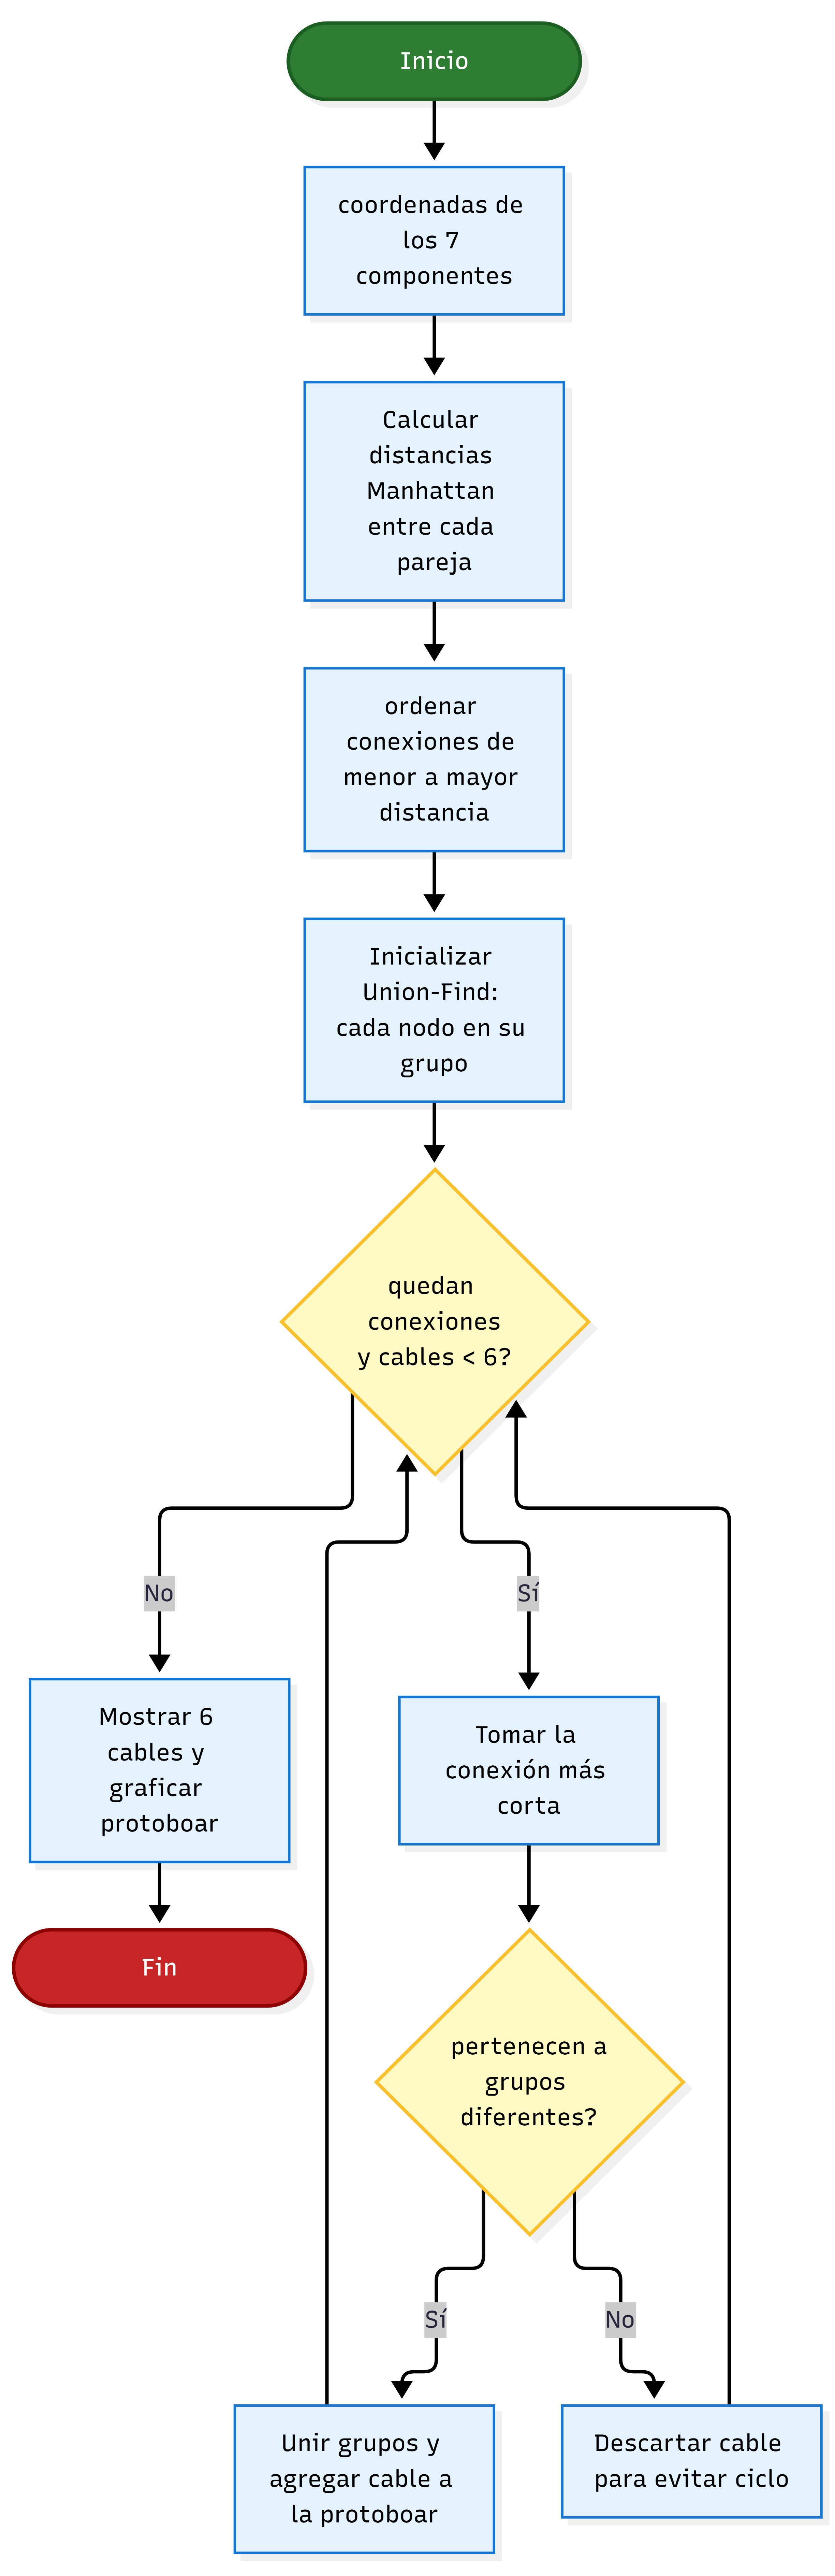

### 5) Análisis de complejidad [15 pts]

- Generación de aristas: Hay 7 componentes, por lo que se generan 21 parejas posibles: O(V^2).
- Ordenamiento: Ordenar las aristas toma O(E log E).
- Union-Find: Las operaciones find y union son casi instantáneas: O(E * alpha(V)).
- Tiempo total: O(E log E), donde E es el número de aristas.
- Mejor caso: Cuando las aristas más cortas conectan todo sin ciclos redundantes.
- Peor caso: Cuando muchas aristas cortas forman ciclos y toca revisar casi todas las aristas.

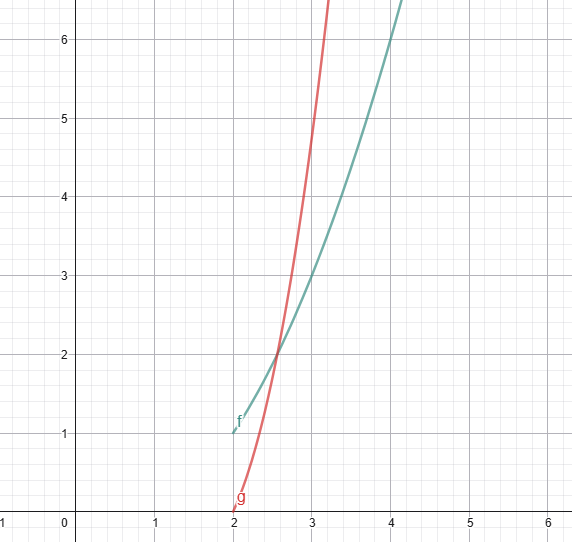

## 6) Código funcional [15 pts]

Punto 1


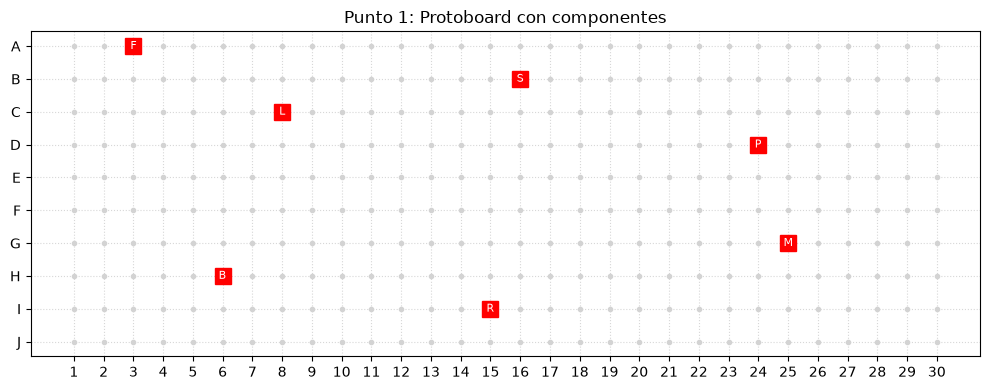

Puntos 2 y 3


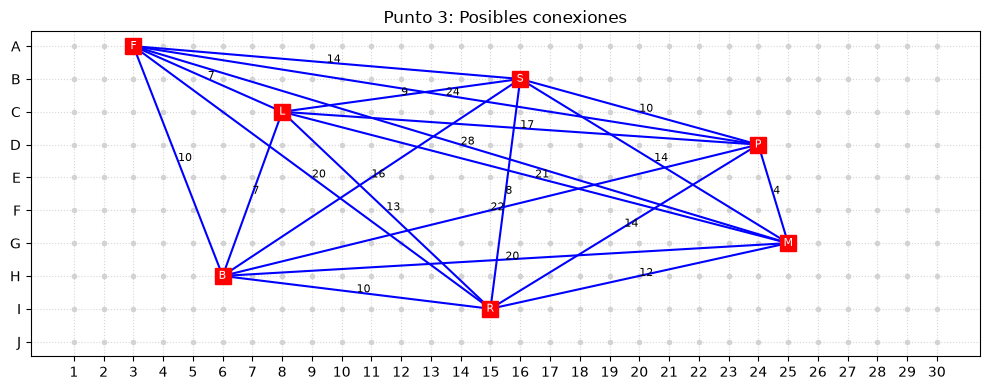

Puntos 4 y 5
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Longitud total de cable: 45


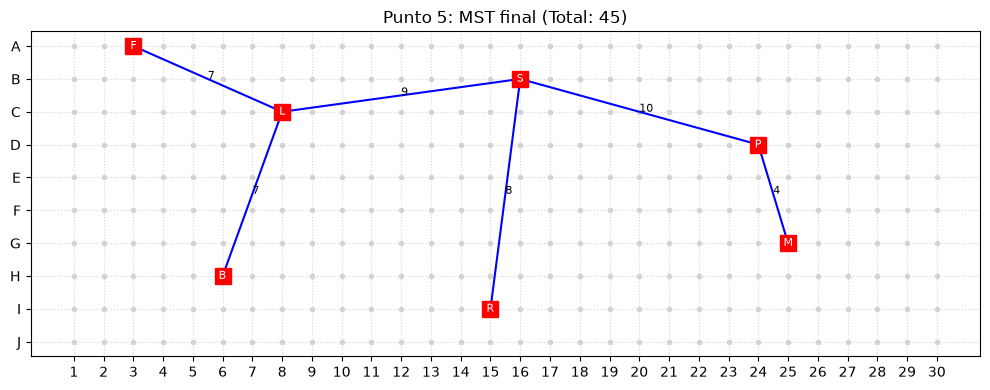

Punto 6
MST original: 45
MST despues del cambio: 42
La cantidad total de cable disminuyo en 3 unidades.


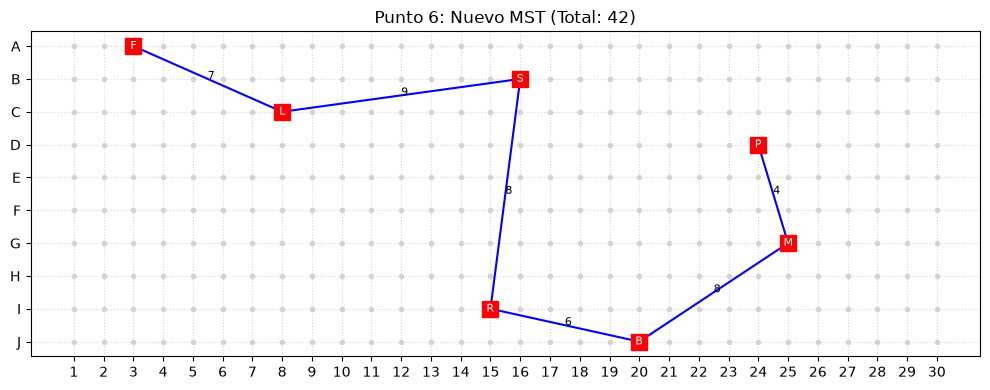

In [1]:
import matplotlib.pyplot as plt

filas = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7, 'H': 8, 'I': 9, 'J': 10}
filas_inv = {v: k for k, v in filas.items()}

def obtener_coordenada(pos):
    return int(pos[1:]), filas[pos[0]]

def distancia(p1, p2):
    return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])

def find(padre, x):
    if padre[x] != x:
        padre[x] = find(padre, padre[x])
    return padre[x]

def union(padre, x, y):
    rx = find(padre, x)
    ry = find(padre, y)
    if rx != ry:
        padre[rx] = ry
        return True
    return False

def kruskal(comp_dict):
    nodos = list(comp_dict.keys())
    pos = {k: obtener_coordenada(v) for k, v in comp_dict.items()}
    aristas = []
    for i in range(len(nodos)):
        for j in range(i + 1, len(nodos)):
            u, v = nodos[i], nodos[j]
            d = distancia(pos[u], pos[v])
            aristas.append((d, u, v))
    aristas.sort()
    padre = {k: k for k in nodos}
    mst = []
    total = 0
    for d, u, v in aristas:
        if union(padre, u, v):
            mst.append((d, u, v))
            total += d
            if len(mst) == len(nodos) - 1:
                break
    return pos, aristas, mst, total

def dibujar(pos, aristas, titulo, ver_pesos=False):
    plt.figure(figsize=(10, 4))
    for col in range(1, 31):
        for fil in range(1, 11):
            plt.plot(col, fil, 'o', color='lightgray', markersize=3)
    if aristas:
        for d, u, v in aristas:
            p1 = pos[u]
            p2 = pos[v]
            plt.plot([p1[0], p2[0]], [p1[1], p2[1]], color='blue', linewidth=1.5)
            if ver_pesos:
                xm = (p1[0] + p2[0]) / 2
                ym = (p1[1] + p2[1]) / 2
                plt.text(xm, ym, str(d), fontsize=8, color='black')
    for k, p in pos.items():
        plt.plot(p[0], p[1], 's', color='red', markersize=12)
        plt.text(p[0], p[1], k, color='white', fontsize=8, ha='center', va='center')
    plt.title(titulo)
    plt.xticks(range(1, 31))
    plt.yticks(range(1, 11), [filas_inv[i] for i in range(1, 11)])
    plt.gca().invert_yaxis()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

componentes = {
    'F': 'A3',
    'L': 'C8',
    'S': 'B16',
    'P': 'D24',
    'B': 'H6',
    'R': 'I15',
    'M': 'G25'
}

pos, aristas, mst, total = kruskal(componentes)

print("Punto 1")
dibujar(pos, [], "Punto 1: Protoboard con componentes")

print("Puntos 2 y 3")
dibujar(pos, aristas, "Punto 3: Posibles conexiones", ver_pesos=True)

print("Puntos 4 y 5")
for i, (d, u, v) in enumerate(mst, 1):
    print(f"Cable {i}: {u} - {v} = {d}")
print(f"Longitud total de cable: {total}")
dibujar(pos, mst, f"Punto 5: MST final (Total: {total})", ver_pesos=True)

print("Punto 6")
componentes_nuevo = componentes.copy()
componentes_nuevo['B'] = 'J20'
pos2, aristas2, mst2, total2 = kruskal(componentes_nuevo)

print(f"MST original: {total}")
print(f"MST despues del cambio: {total2}")
if total2 > total:
    print(f"La cantidad total de cable aumento en {total2 - total} unidades.")
elif total2 < total:
    print(f"La cantidad total de cable disminuyo en {total - total2} unidades.")
else:
    print("La cantidad total de cable no cambio.")

dibujar(pos2, mst2, f"Punto 6: Nuevo MST (Total: {total2})", ver_pesos=True)

## 7) Tests aplicados [15 pts]

In [2]:
assert distancia(obtener_coordenada('A3'), obtener_coordenada('C8')) == 7
assert len(mst) == 6
assert total > 0
assert len(mst2) == 6
assert total != total2
print("Todos los tests pasaron correctamente.")

Todos los tests pasaron correctamente.
